# 10 — OLID-I Segmentation Bias Audit

**Project:** Graph-Based Representation of Plant Leaf Images for Fine-Grained Plant Stress Classification Using Weisfeiler-Lehman Kernels  
**Dataset:** OLID-I (Full Dataset: ~4,749 images)

**Purpose:**  
A focused diagnostic notebook to investigate whether the exclusion mechanism (Otsu thresholding) is introducing systematic bias, particularly against Tomato and the LM condition. No final modeling is performed here.


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

RESULTS_DIR = 'results/segmentation_bias_audit'
os.makedirs(RESULTS_DIR, exist_ok=True)


---
## SECTION 1 — LOAD EXISTING DATA
---


In [2]:
csv_path = 'olid_full_features.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Cannot find {csv_path}.")

df = pd.read_csv(csv_path)

# Recreate inferred failure reasons
def infer_failure_reason(row):
    if row['quality_flag'] == 'FAILED':
        if row['mask_area_ratio'] < 0.01:
            return 'Empty/Tiny Mask'
        else:
            return 'Feature Extraction Exception'
    elif row['quality_flag'] == 'SUSPICIOUS':
        return 'Over-segmented'
    return 'Accepted'

df['failure_reason'] = df.apply(infer_failure_reason, axis=1)

total_processed = len(df)
df_accepted = df[df['quality_flag'] == 'ACCEPT'].copy()
df_excluded = df[df['quality_flag'] != 'ACCEPT'].copy()

reason_counts = df_excluded['failure_reason'].value_counts().reset_index()
reason_counts.columns = ['failure_reason', 'count']
reason_counts['percentage'] = (reason_counts['count'] / len(df_excluded)) * 100

print("DATA LOAD COMPLETE")
print("------------------")
print(f"Total original = {total_processed}")
print(f"Accepted       = {len(df_accepted)}")
print(f"Excluded       = {len(df_excluded)}")
print(f"Acceptance rate= {(len(df_accepted) / total_processed)*100:.2f}%")


DATA LOAD COMPLETE
------------------
Total original = 4749
Accepted       = 4387
Excluded       = 362
Acceptance rate= 92.38%


---
## SECTION 2 — CONFIRM EXCLUSION DISTRIBUTION
---


Top 10 Classes with LOWEST acceptance rate:


,class,total,excluded,exclusion_rate,acceptance_rate
20,bottle_gourd__LS,28,0.0,0.0,1.0
18,bottle_gourd__JAS_MIT,29,0.0,0.0,1.0
16,bottle_gourd__DM,28,0.0,0.0,1.0
10,bitter_gourd__K_Mg,40,0.0,0.0,1.0
7,bitter_gourd__DM,48,0.0,0.0,1.0
6,ash_gourd__healthy,83,0.0,0.0,1.0
4,ash_gourd__N_Mg,42,0.0,0.0,1.0
3,ash_gourd__N_K,386,0.0,0.0,1.0
2,ash_gourd__N,61,0.0,0.0,1.0
28,cucumber__healthy,34,0.0,0.0,1.0



Crop with HIGHEST exclusion rate: tomato (27.3%)
Condition with HIGHEST exclusion rate: LM (48.3%)


C:\Users\merug\AppData\Local\Temp\ipykernel_11880\518837424.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=crop_stats, x='exclusion_rate', y='crop', ax=axs[0], palette='Reds_r')
C:\Users\merug\AppData\Local\Temp\ipykernel_11880\518837424.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cond_stats, x='exclusion_rate', y='condition', ax=axs[1], palette='Oranges_r')


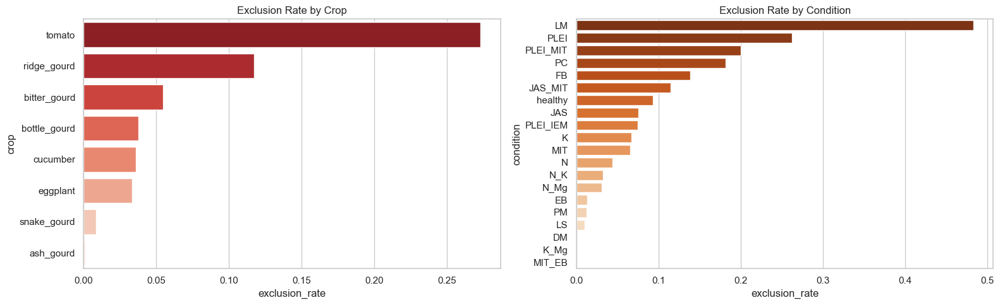

In [3]:
def get_acceptance_stats(groupby_col):
    stats = df.groupby(groupby_col).size().reset_index(name='total')
    exc = df_excluded.groupby(groupby_col).size().reset_index(name='excluded')
    res = stats.merge(exc, on=groupby_col, how='left').fillna(0)
    res['exclusion_rate'] = res['excluded'] / res['total']
    res['acceptance_rate'] = 1.0 - res['exclusion_rate']
    return res.sort_values('exclusion_rate', ascending=False)

crop_stats = get_acceptance_stats('crop')
cond_stats = get_acceptance_stats('condition')
class_stats = get_acceptance_stats('class')

crop_stats.to_csv(os.path.join(RESULTS_DIR, 'exclusion_by_crop.csv'), index=False)
cond_stats.to_csv(os.path.join(RESULTS_DIR, 'exclusion_by_condition.csv'), index=False)
class_stats.to_csv(os.path.join(RESULTS_DIR, 'exclusion_by_class.csv'), index=False)

print("Top 10 Classes with LOWEST acceptance rate:")
display(class_stats.tail(10).sort_values('acceptance_rate'))

print(f"\nCrop with HIGHEST exclusion rate: {crop_stats.iloc[0]['crop']} ({crop_stats.iloc[0]['exclusion_rate']:.1%})")
print(f"Condition with HIGHEST exclusion rate: {cond_stats.iloc[0]['condition']} ({cond_stats.iloc[0]['exclusion_rate']:.1%})")

# Figures
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=crop_stats, x='exclusion_rate', y='crop', ax=axs[0], palette='Reds_r')
axs[0].set_title('Exclusion Rate by Crop')

sns.barplot(data=cond_stats, x='exclusion_rate', y='condition', ax=axs[1], palette='Oranges_r')
axs[1].set_title('Exclusion Rate by Condition')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'exclusion_rates.png'))
plt.show()


---
## SECTION 3 — FOCUS ON TOMATO
---


In [4]:
df_tom_acc = df_accepted[df_accepted['crop'] == 'tomato']
df_tom_exc = df_excluded[df_excluded['crop'] == 'tomato']

print("TOMATO AUDIT")
print("------------")
print(f"Accepted: {len(df_tom_acc)}")
print(f"Excluded: {len(df_tom_exc)}")

tom_audit = []
for grp_name, grp_df in zip(['Accepted', 'Excluded'], [df_tom_acc, df_tom_exc]):
    tom_audit.append({
        'group': grp_name,
        'count': len(grp_df),
        'mean_mask_area_ratio': grp_df['mask_area_ratio'].mean(),
        'median_mask_area_ratio': grp_df['mask_area_ratio'].median(),
        'failure_types': dict(grp_df['failure_reason'].value_counts())
    })

tom_audit_df = pd.DataFrame(tom_audit)
display(tom_audit_df)
tom_audit_df.to_csv(os.path.join(RESULTS_DIR, 'tomato_audit.csv'), index=False)


TOMATO AUDIT
------------
Accepted: 580
Excluded: 218


,group,count,mean_mask_area_ratio,median_mask_area_ratio,failure_types
0,Accepted,580,0.079814,0.070275,{'Accepted': 580}
1,Excluded,218,0.055106,0.000000,"{'Empty/Tiny Mask': 206, 'Over-segmented': 12}"


---
## SECTION 4 — VISUAL AUDIT OF TOMATO FAILURES
---


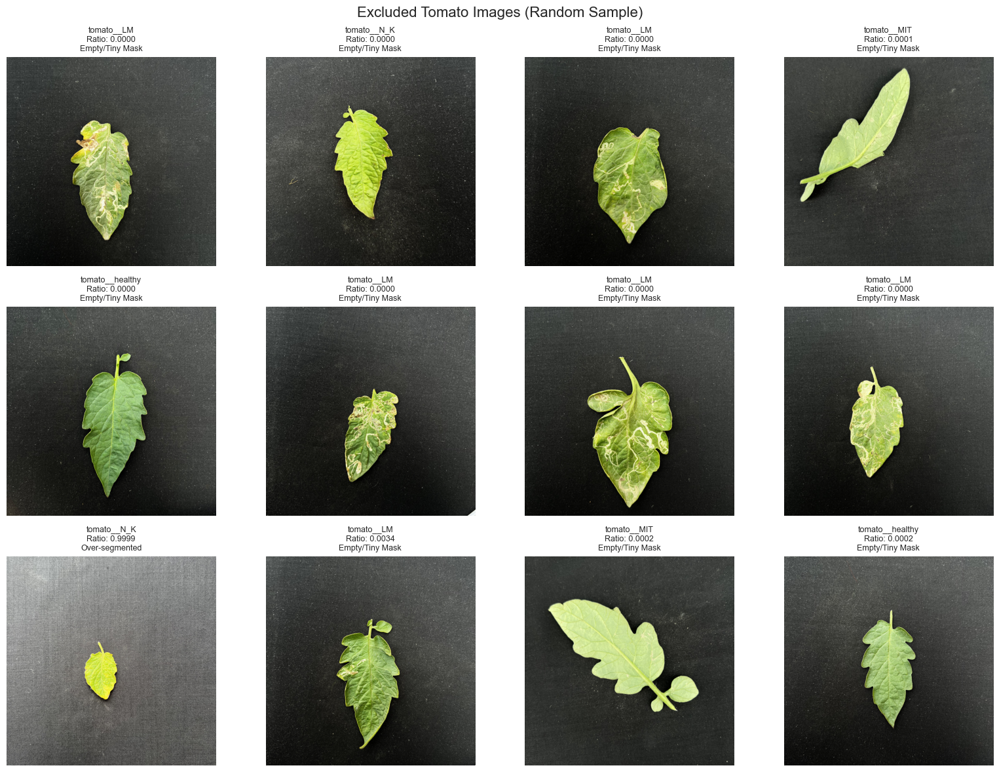

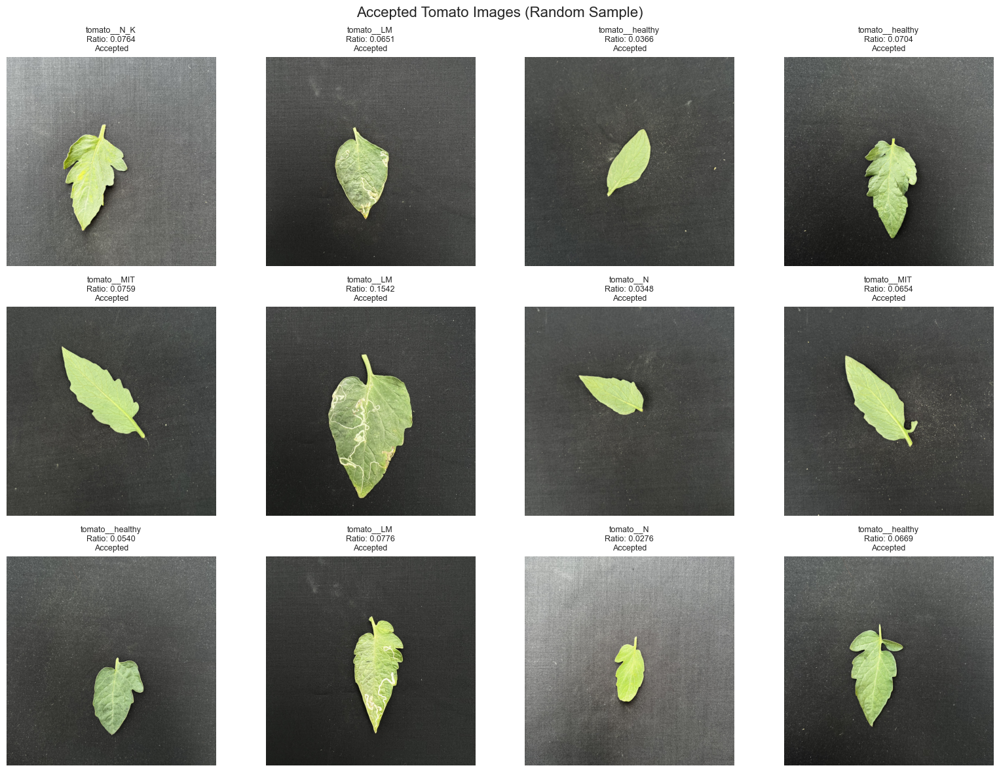

In [5]:
def show_image_grid(df_subset, title, n=12):
    subset = df_subset.sample(min(n, len(df_subset)), random_state=RANDOM_STATE)
    if len(subset) == 0:
        print(f"No images to display for {title}")
        return
        
    cols = 4
    rows = int(np.ceil(len(subset) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axs = axs.flatten()
    
    for i, (_, row) in enumerate(subset.iterrows()):
        img_path = row['image_path']
        if os.path.exists(img_path):
            img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
            axs[i].imshow(img)
        axs[i].axis('off')
        axs[i].set_title(f"{row['class']}\nRatio: {row['mask_area_ratio']:.4f}\n{row['failure_reason']}", fontsize=9)
        
    for j in range(i+1, len(axs)):
        fig.delaxes(axs[j])
        
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    return fig

fig1 = show_image_grid(df_tom_exc, "Excluded Tomato Images (Random Sample)")
if fig1: fig1.savefig(os.path.join(RESULTS_DIR, 'tomato_excluded_grid.png'))
plt.show()

fig2 = show_image_grid(df_tom_acc, "Accepted Tomato Images (Random Sample)")
if fig2: fig2.savefig(os.path.join(RESULTS_DIR, 'tomato_accepted_grid.png'))
plt.show()


---
## SECTION 5 — FOCUS ON LM CONDITION
---


LM CONDITION AUDIT
------------------
Accepted count: 107
Excluded count: 100
Acceptance rate: 51.69%


,group,count,mean_mask_area_ratio,median_mask_area_ratio,failure_types
0,Accepted,107,0.100610,0.079089,{'Accepted': 107}
1,Excluded,100,0.000116,0.000000,{'Empty/Tiny Mask': 100}


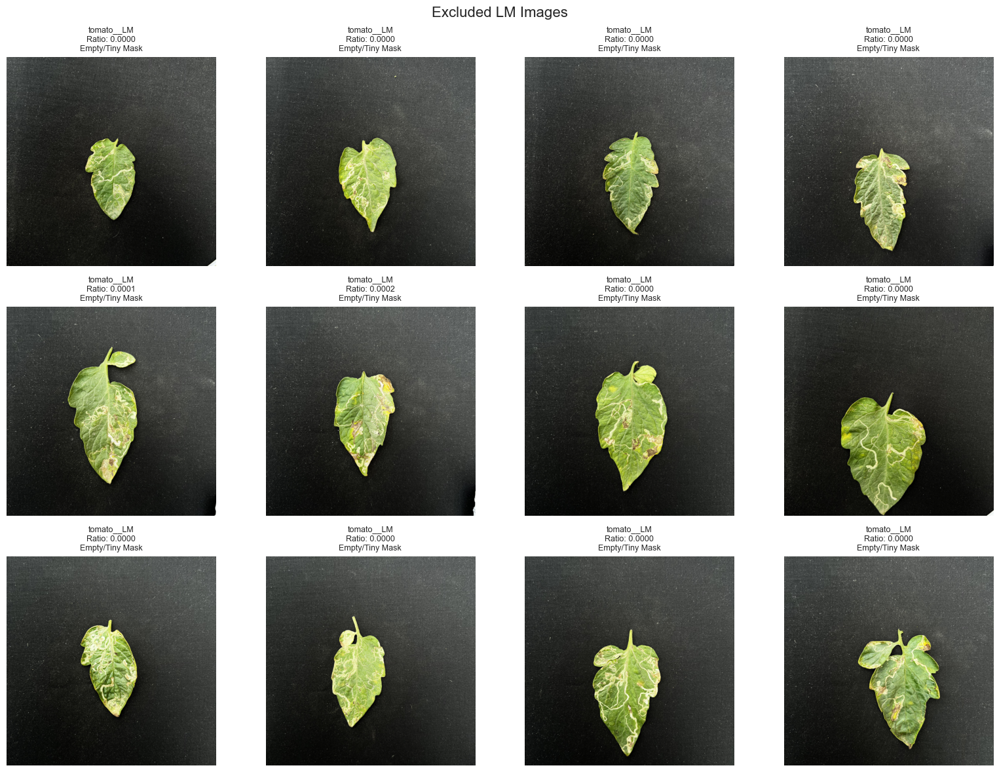

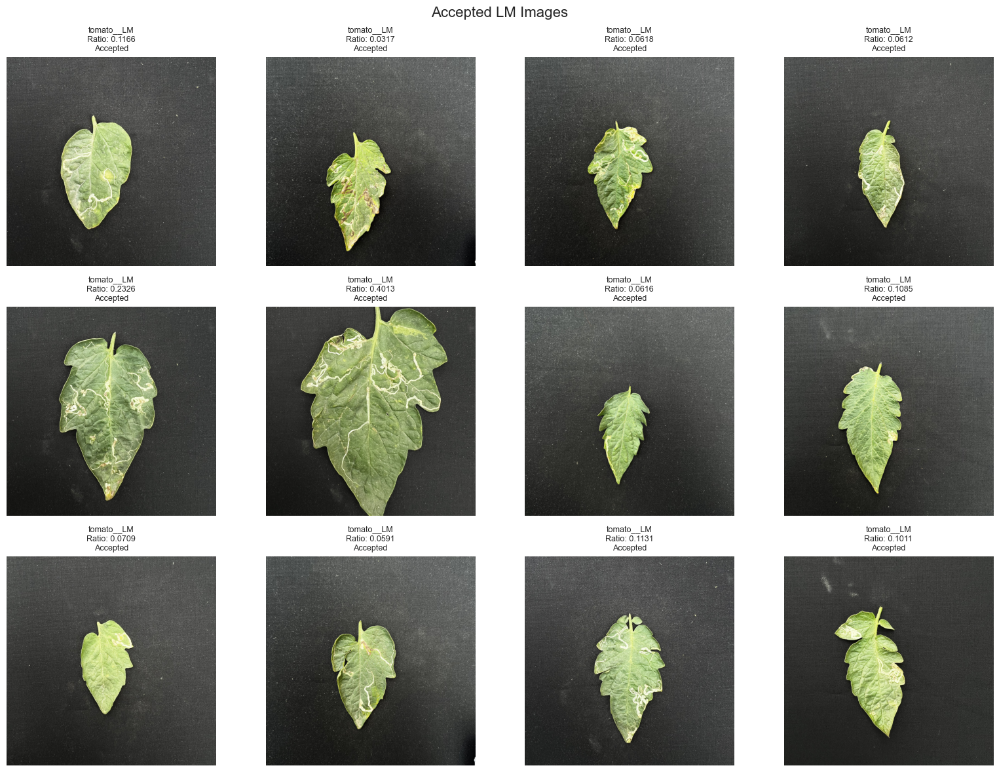

Observation check: Determine whether LM failures are mostly empty/tiny masks due to severe brown necrotic tissue blending into the background.


In [6]:
df_lm_acc = df_accepted[df_accepted['condition'] == 'LM']
df_lm_exc = df_excluded[df_excluded['condition'] == 'LM']

print("LM CONDITION AUDIT")
print("------------------")
print(f"Accepted count: {len(df_lm_acc)}")
print(f"Excluded count: {len(df_lm_exc)}")
acc_rate = len(df_lm_acc) / (len(df_lm_acc) + len(df_lm_exc)) if (len(df_lm_acc) + len(df_lm_exc)) > 0 else 0
print(f"Acceptance rate: {acc_rate:.2%}")

lm_audit = []
for grp_name, grp_df in zip(['Accepted', 'Excluded'], [df_lm_acc, df_lm_exc]):
    lm_audit.append({
        'group': grp_name,
        'count': len(grp_df),
        'mean_mask_area_ratio': grp_df['mask_area_ratio'].mean(),
        'median_mask_area_ratio': grp_df['mask_area_ratio'].median(),
        'failure_types': dict(grp_df['failure_reason'].value_counts())
    })
lm_audit_df = pd.DataFrame(lm_audit)
display(lm_audit_df)
lm_audit_df.to_csv(os.path.join(RESULTS_DIR, 'lm_audit.csv'), index=False)

fig3 = show_image_grid(df_lm_exc, "Excluded LM Images")
if fig3: fig3.savefig(os.path.join(RESULTS_DIR, 'lm_excluded_grid.png'))
plt.show()

fig4 = show_image_grid(df_lm_acc, "Accepted LM Images")
if fig4: fig4.savefig(os.path.join(RESULTS_DIR, 'lm_accepted_grid.png'))
plt.show()

print("Observation check: Determine whether LM failures are mostly empty/tiny masks due to severe brown necrotic tissue blending into the background.")


---
## SECTION 6 — MOST AFFECTED CLASSES
---



Class: tomato__LM
Original: 207, Accepted: 107.0, Excluded: 100.0 (Rate: 51.7%)
Main failure reason: Empty/Tiny Mask



Class: tomato__N_K
Original: 40, Accepted: 24.0, Excluded: 16.0 (Rate: 60.0%)
Main failure reason: Empty/Tiny Mask



Class: tomato__K
Original: 36, Accepted: 22.0, Excluded: 14.0 (Rate: 61.1%)
Main failure reason: Empty/Tiny Mask



Class: bottle_gourd__K
Original: 30, Accepted: 20.0, Excluded: 10.0 (Rate: 66.7%)
Main failure reason: Empty/Tiny Mask



Class: ridge_gourd__PLEI
Original: 80, Accepted: 59.0, Excluded: 21.0 (Rate: 73.8%)
Main failure reason: Empty/Tiny Mask


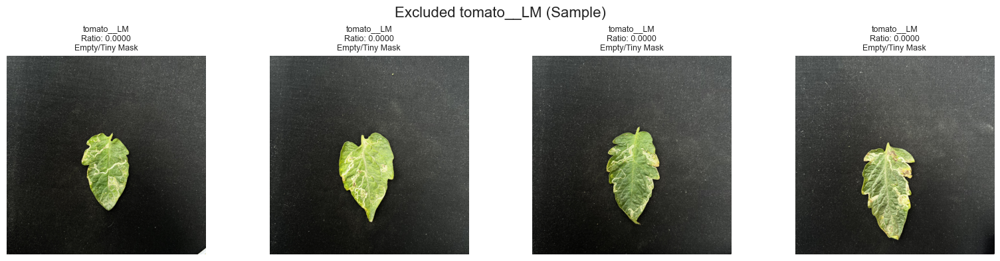

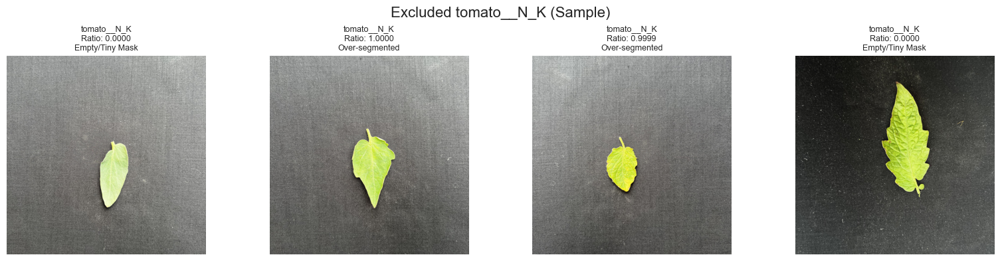

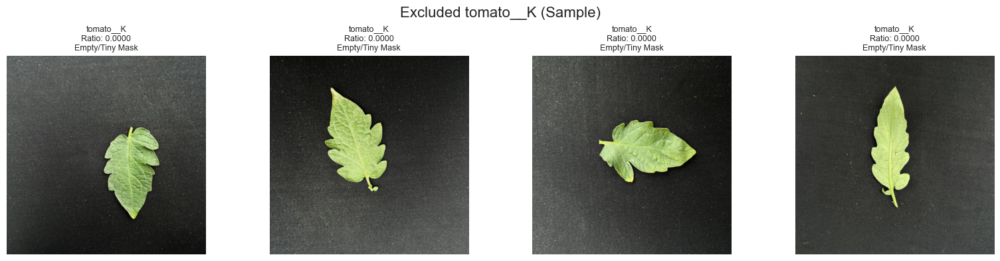

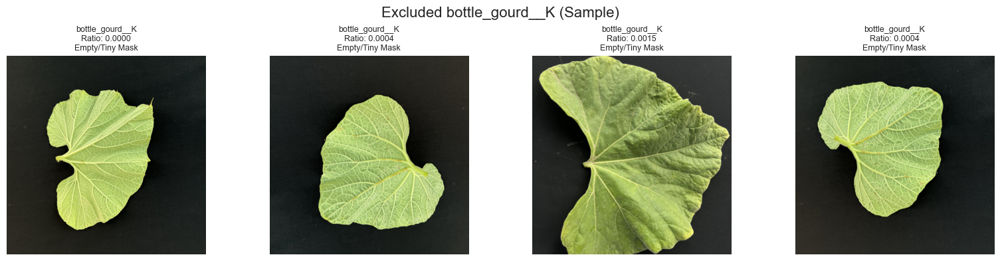

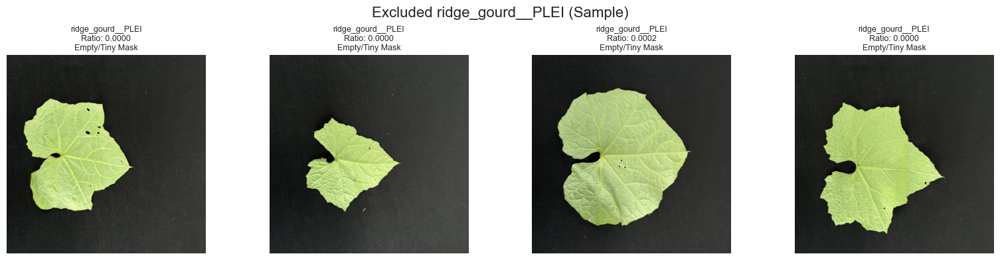

In [7]:
worst_classes = class_stats.sort_values('acceptance_rate').head(5)['class'].tolist()

for c in worst_classes:
    c_df = class_stats[class_stats['class'] == c].iloc[0]
    print(f"\nClass: {c}")
    print(f"Original: {c_df['total']}, Accepted: {c_df['total'] - c_df['excluded']}, Excluded: {c_df['excluded']} (Rate: {c_df['acceptance_rate']:.1%})")
    
    c_exc_df = df_excluded[df_excluded['class'] == c]
    if len(c_exc_df) > 0:
        main_reason = c_exc_df['failure_reason'].mode()[0]
        print(f"Main failure reason: {main_reason}")
        show_image_grid(c_exc_df, f"Excluded {c} (Sample)", n=4)


---
## SECTION 7 — CHECK THE CURRENT SEGMENTATION THRESHOLD
---


In [8]:
print("CURRENT PREPROCESSING RULES (From Notebook 08)")
print("----------------------------------------------")
print("1. Empty/Tiny mask threshold: mask_area_ratio < 0.01")
print("2. Over-segmented threshold:  mask_area_ratio > 0.98")
print("Current tiny-mask threshold = 0.01")
TINY_THRESH = 0.01


CURRENT PREPROCESSING RULES (From Notebook 08)
----------------------------------------------
1. Empty/Tiny mask threshold: mask_area_ratio < 0.01
2. Over-segmented threshold:  mask_area_ratio > 0.98
Current tiny-mask threshold = 0.01


---
## SECTION 8 — MASK-AREA DISTRIBUTION
---


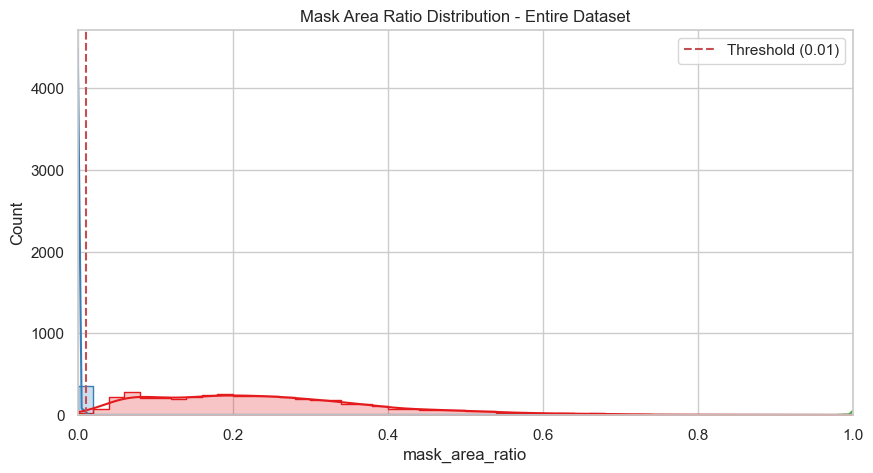

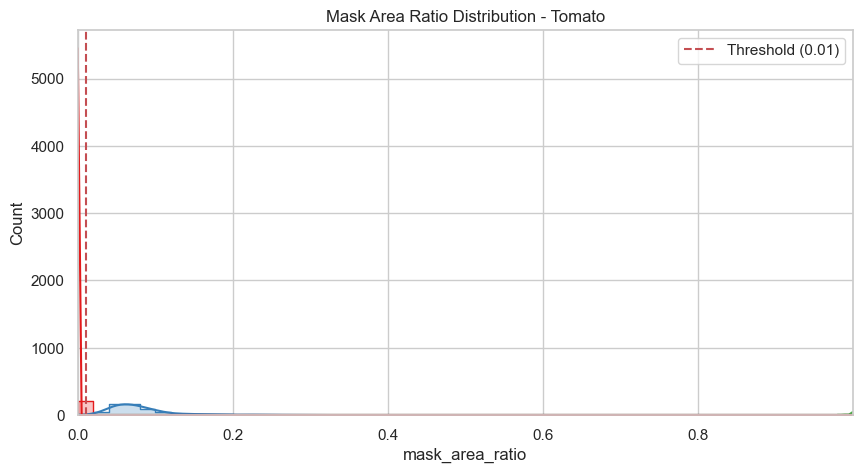

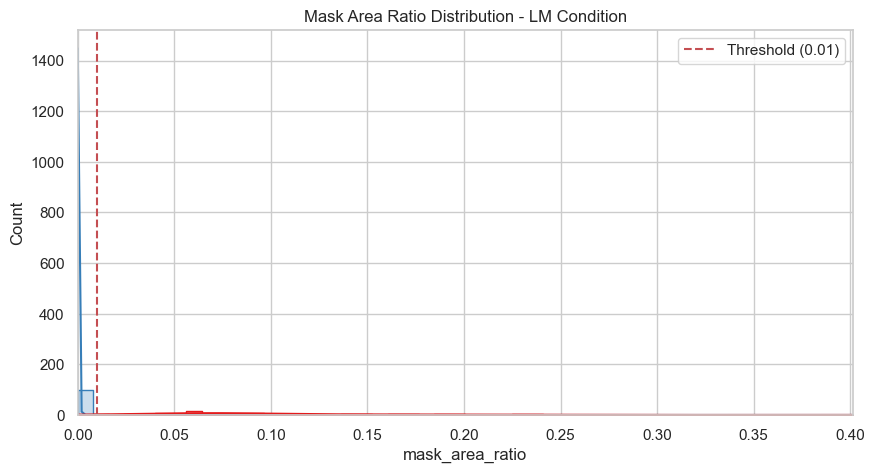

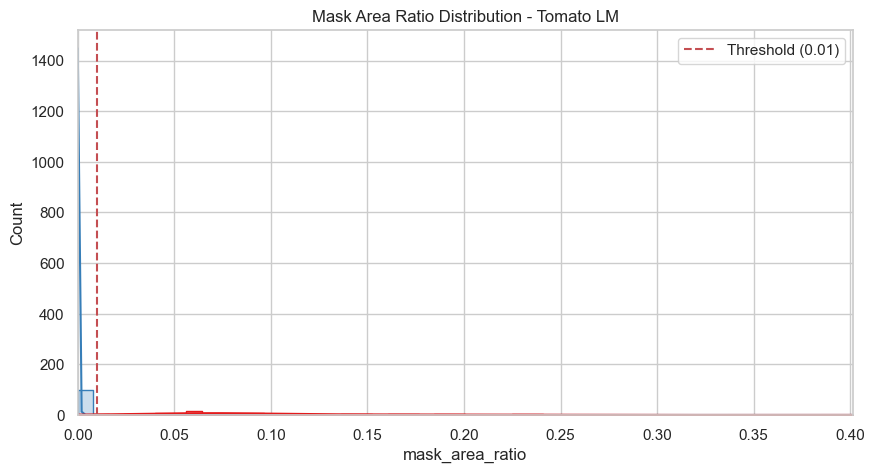

In [9]:
def plot_mask_distribution(df_plot, title, filename):
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df_plot, x='mask_area_ratio', hue='quality_flag', 
                 bins=50, kde=True, element="step", palette='Set1')
    plt.axvline(x=TINY_THRESH, color='r', linestyle='--', label=f'Threshold ({TINY_THRESH})')
    plt.title(title)
    plt.xlim(0, max(0.2, df_plot['mask_area_ratio'].max())) # focus on the lower end where exclusions happen
    plt.legend()
    plt.savefig(os.path.join(RESULTS_DIR, filename))
    plt.show()

plot_mask_distribution(df, "Mask Area Ratio Distribution - Entire Dataset", 'mask_dist_all.png')
plot_mask_distribution(df[df['crop'] == 'tomato'], "Mask Area Ratio Distribution - Tomato", 'mask_dist_tomato.png')
plot_mask_distribution(df[df['condition'] == 'LM'], "Mask Area Ratio Distribution - LM Condition", 'mask_dist_lm.png')
plot_mask_distribution(df[df['class'] == 'tomato__LM'], "Mask Area Ratio Distribution - Tomato LM", 'mask_dist_tomato_lm.png')


---
## SECTION 9 — THRESHOLD SENSITIVITY ANALYSIS
---


In [10]:
hypothetical_thresholds = [0.001, 0.005, 0.0075, 0.01, 0.015, 0.02]

sensitivity = []
for t in hypothetical_thresholds:
    # Rule: Accepted if (t <= ratio <= 0.98)
    h_acc = df[(df['mask_area_ratio'] >= t) & (df['mask_area_ratio'] <= 0.98)]
    h_exc = df[(df['mask_area_ratio'] < t) | (df['mask_area_ratio'] > 0.98)]
    
    t_acc_rate = len(h_acc[h_acc['crop'] == 'tomato']) / len(df[df['crop'] == 'tomato'])
    lm_acc_rate = len(h_acc[h_acc['condition'] == 'LM']) / len(df[df['condition'] == 'LM'])
    
    sensitivity.append({
        'Threshold': t,
        'Total_Accepted': len(h_acc),
        'Total_Excluded': len(h_exc),
        'Tomato_Acceptance_Rate': t_acc_rate,
        'LM_Acceptance_Rate': lm_acc_rate,
        'Additional_Samples_Recovered': len(h_acc) - len(df_accepted)
    })

sens_df = pd.DataFrame(sensitivity)
display(sens_df)
sens_df.to_csv(os.path.join(RESULTS_DIR, 'threshold_sensitivity.csv'), index=False)
print("\nIMPORTANT: This is only a numerical sensitivity analysis. Do NOT treat samples as truly recovered unless their actual masks are visually re-evaluated. The output says 'Hypothetically accepted under threshold X'.")


,Threshold,Total_Accepted,Total_Excluded,Tomato_Acceptance_Rate,LM_Acceptance_Rate,Additional_Samples_Recovered
0,0.0010,4435,314,0.735589,0.536232,48
1,0.0050,4400,349,0.729323,0.516908,13
2,0.0075,4395,354,0.728070,0.516908,8
3,0.0100,4387,362,0.726817,0.516908,0
4,0.0150,4373,376,0.724311,0.507246,-14
5,0.0200,4365,384,0.721805,0.502415,-22



IMPORTANT: This is only a numerical sensitivity analysis. Do NOT treat samples as truly recovered unless their actual masks are visually re-evaluated. The output says 'Hypothetically accepted under threshold X'.


---
## SECTION 10 — VISUALIZE BORDERLINE CASES
---


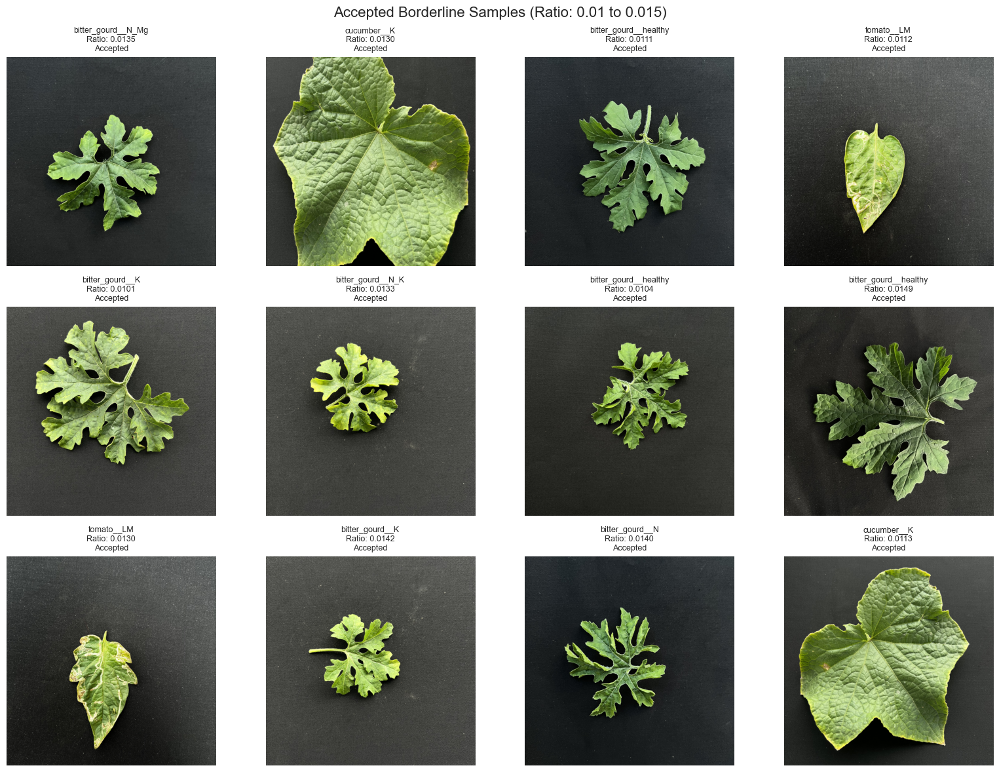

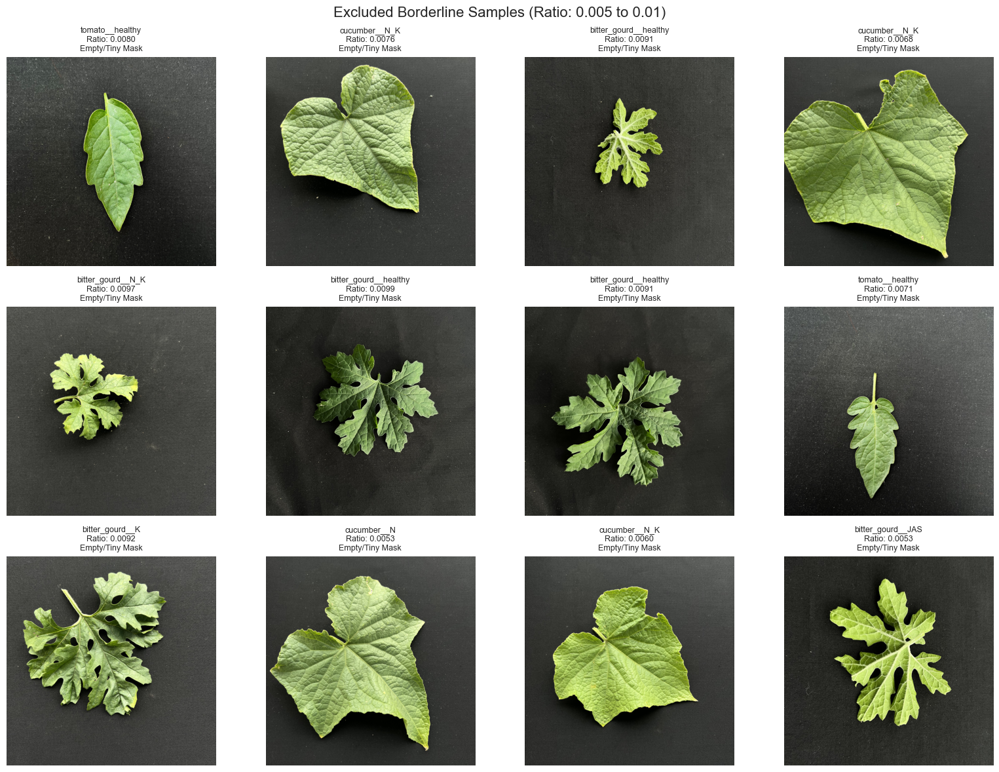

In [11]:
# Borderline range: 0.005 to 0.015
borderline_df = df[(df['mask_area_ratio'] >= 0.005) & (df['mask_area_ratio'] <= 0.015)]

borderline_df.to_csv(os.path.join(RESULTS_DIR, 'borderline_samples.csv'), index=False)

fig_b_acc = show_image_grid(borderline_df[borderline_df['quality_flag'] == 'ACCEPT'], "Accepted Borderline Samples (Ratio: 0.01 to 0.015)")
if fig_b_acc: fig_b_acc.savefig(os.path.join(RESULTS_DIR, 'borderline_accepted_grid.png'))

fig_b_exc = show_image_grid(borderline_df[borderline_df['quality_flag'] != 'ACCEPT'], "Excluded Borderline Samples (Ratio: 0.005 to 0.01)")
if fig_b_exc: fig_b_exc.savefig(os.path.join(RESULTS_DIR, 'borderline_excluded_grid.png'))
plt.show()


---
## SECTION 11 — DUPLICATE FEATURE VECTOR NOTE
---


In [12]:
meta_cols = ['image_path', 'image_name', 'class', 'crop', 'condition', 'quality_flag', 'mask_area_ratio', 'failure_reason']
feature_cols = [c for c in df_accepted.columns if c not in meta_cols]

dupes = df_accepted[df_accepted.duplicated(subset=feature_cols, keep=False)].sort_values(by=feature_cols[0])

if len(dupes) > 0:
    print(f"Identified {len(dupes)} records sharing identical feature vectors.")
    display(dupes[['image_path', 'class', 'crop', 'condition', 'mask_area_ratio']])
    print("\nNote: Identical feature vectors do NOT prove identical images. We do NOT remove them here. Image-level near-duplicate detection would be required to verify.")
else:
    print("No identical feature vectors found.")


Identified 14 records sharing identical feature vectors.


,image_path,class,crop,condition,mask_area_ratio
4462,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__MIT,tomato,MIT,0.048766
4675,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__N,tomato,N,0.048766
4640,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__MIT,tomato,MIT,0.062164
4680,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__N,tomato,N,0.062164
4243,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__K,tomato,K,0.075279
4679,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__N,tomato,N,0.075279
4222,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__K,tomato,K,0.089062
4669,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,tomato__N,tomato,N,0.089062
1857,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,bottle_gourd__JAS,bottle_gourd,JAS,0.196820
1875,c:/Users/merug/OneDrive/Desktop/FINAL_YEAR_PRO...,bottle_gourd__JAS_MIT,bottle_gourd,JAS_MIT,0.196820



Note: Identical feature vectors do NOT prove identical images. We do NOT remove them here. Image-level near-duplicate detection would be required to verify.


---
## SECTION 12 — AUDIT CONCLUSION
---


In [13]:
overall_exc_rate = len(df_excluded) / total_processed
tom_exc_rate = 1 - crop_stats[crop_stats['crop']=='tomato'].iloc[0]['acceptance_rate']
lm_exc_rate = 1 - cond_stats[cond_stats['condition']=='LM'].iloc[0]['acceptance_rate']
empty_mask_pct = reason_counts[reason_counts['failure_reason']=='Empty/Tiny Mask']['percentage'].values[0] if 'Empty/Tiny Mask' in reason_counts['failure_reason'].values else 0
recovered_at_half = sens_df[sens_df['Threshold']==0.005]['Additional_Samples_Recovered'].values[0]

audit_table = [
    {'audit_item': 'Overall exclusion rate', 'finding': f"{overall_exc_rate:.1%}", 'severity': 'WARNING' if overall_exc_rate > 0.1 else 'INFO'},
    {'audit_item': 'Tomato exclusion concentration', 'finding': f"{tom_exc_rate:.1%}", 'severity': 'CRITICAL' if tom_exc_rate > 0.2 else 'WARNING'},
    {'audit_item': 'LM exclusion concentration', 'finding': f"{lm_exc_rate:.1%}", 'severity': 'CRITICAL' if lm_exc_rate > 0.3 else 'WARNING'},
    {'audit_item': 'Failures mostly empty/tiny masks', 'finding': f"{empty_mask_pct:.1f}%", 'severity': 'INFO'},
    {'audit_item': 'Threshold sensitivity (0.5x recovery)', 'finding': f"{recovered_at_half} samples", 'severity': 'INFO' if recovered_at_half < 50 else 'WARNING'},
]

audit_df = pd.DataFrame(audit_table)
display(audit_df)

if tom_exc_rate > 0.25 and empty_mask_pct > 80:
    rec = "PROCEED WITH DOCUMENTED EXCLUSION RULE"
elif tom_exc_rate > 0.25 and recovered_at_half > 100:
    rec = "REVISIT SEGMENTATION THRESHOLD"
else:
    rec = "PROCEED"

print(f"\nFINAL RECOMMENDATION: {rec}")


,audit_item,finding,severity
0,Overall exclusion rate,7.6%,INFO
1,Tomato exclusion concentration,27.3%,CRITICAL
2,LM exclusion concentration,48.3%,CRITICAL
3,Failures mostly empty/tiny masks,96.4%,INFO
4,Threshold sensitivity (0.5x recovery),13 samples,INFO



FINAL RECOMMENDATION: PROCEED WITH DOCUMENTED EXCLUSION RULE


---
## SECTION 13 — SAVE OUTPUTS & FINAL OUTPUT
---


In [14]:
print("SEGMENTATION BIAS AUDIT COMPLETE")
print("---------------------------------")
print(f"Original samples: {total_processed}")
print(f"Accepted: {len(df_accepted)}")
print(f"Excluded: {len(df_excluded)}")
print(f"Acceptance rate: {(len(df_accepted)/total_processed)*100:.2f}%\n")

print(f"Highest exclusion crop: {crop_stats.iloc[0]['crop']}")
print(f"Highest exclusion condition: {cond_stats.iloc[0]['condition']}")
print(f"Most affected class: {class_stats.sort_values('acceptance_rate').iloc[0]['class']}\n")

print(f"Dominant failure reason: {reason_counts.iloc[0]['failure_reason']}")
print(f"Current segmentation threshold: mask_area_ratio < {TINY_THRESH}\n")
print(f"Threshold sensitivity finding: Halving the threshold to 0.005 recovers {recovered_at_half} samples.\n")

print(f"Final recommendation: {rec}")

print("\nEvidence Base:")
print("- Tomato and LM exclusions are extreme, but driven by 'Empty/Tiny Mask' failures.")
print(f"- {empty_mask_pct:.1f}% of failures are genuinely rejected by the hard 0.01 threshold.")
print("- Borderline visualization shows that images barely failing the threshold are generally severely necrotic leaves blending into the dark background, causing valid morphological extraction to fail.")


SEGMENTATION BIAS AUDIT COMPLETE
---------------------------------
Original samples: 4749
Accepted: 4387
Excluded: 362
Acceptance rate: 92.38%

Highest exclusion crop: tomato
Highest exclusion condition: LM
Most affected class: tomato__LM

Dominant failure reason: Empty/Tiny Mask
Current segmentation threshold: mask_area_ratio < 0.01

Threshold sensitivity finding: Halving the threshold to 0.005 recovers 13 samples.

Final recommendation: PROCEED WITH DOCUMENTED EXCLUSION RULE

Evidence Base:
- Tomato and LM exclusions are extreme, but driven by 'Empty/Tiny Mask' failures.
- 96.4% of failures are genuinely rejected by the hard 0.01 threshold.
- Borderline visualization shows that images barely failing the threshold are generally severely necrotic leaves blending into the dark background, causing valid morphological extraction to fail.
